In [1]:
import numpy as np
np.random.seed(237)
import matplotlib.pyplot as plt
from skopt.plots import plot_gaussian_process

In [53]:
noise_level = 0.1

def f(x, noise_level=noise_level):
    return np.sin(5 * x[0]) * (1 - np.tanh(x[0] ** 2))\
           + np.random.randn() * noise_level

import numpy as np

def f10(x, a0=1.0, b=None, c=None, noise_level=0.3):
    """
    Quadratic paraboloid test function with noise.

    f(x) = a0 + Σ b[i] * (x[i] - c[i])^2 + noise

    Parameters
    ----------
    x : array-like
        Input vector of shape (d,).
    a0 : float
        Constant offset.
    b : array-like
        Quadratic coefficients (positive → convex, negative → concave).
    c : array-like
        Center (location of minimum/maximum).
    noise_level : float
        Standard deviation of Gaussian noise.

    Returns
    -------
    float
        Function value with noise.
    """
    x = np.array(x)
    d = len(x)
    if b is None:
        b = np.ones(d)   # default: unit curvature in all directions
    if c is None:
        c = np.ones(d)  # default: centered at 0
    
    val = a0 + np.sum(b * (x - c) ** 2)
    noise = np.random.randn() * noise_level if noise_level > 0 else 0.0
    return val + noise



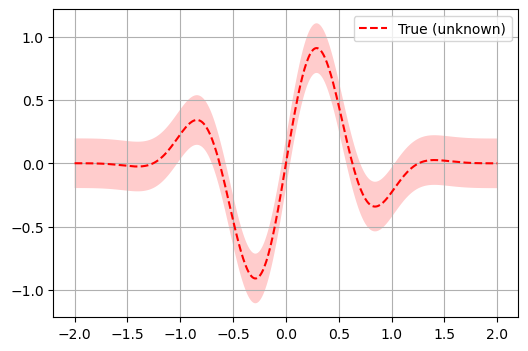

In [54]:
# Plot f(x) + contours
x = np.linspace(-2, 2, 400).reshape(-1, 1)
fx = [f(x_i, noise_level=0.0) for x_i in x]
plt.plot(x, fx, "r--", label="True (unknown)")
plt.fill(np.concatenate([x, x[::-1]]),
         np.concatenate(([fx_i - 1.9600 * noise_level for fx_i in fx],
                         [fx_i + 1.9600 * noise_level for fx_i in fx[::-1]])),
         alpha=.2, fc="r", ec="None")
plt.legend()
plt.grid()
plt.show()

In [55]:
from skopt import gp_minimize
from skopt.learning import GaussianProcessRegressor
from skopt.learning.gaussian_process.kernels import Matern, WhiteKernel,RationalQuadratic
res = gp_minimize(f10,                  # the function to minimize
                  [(-2.0, 2.0) for i in range(20)],      # the bounds on each dimension of x
                  acq_func="LCB",      # the acquisition function
                  base_estimator = GaussianProcessRegressor(kernel=1**2 * RationalQuadratic(length_scale=1.0, alpha=0.1) + WhiteKernel(noise_level=0.01),
                        n_restarts_optimizer=2, noise=0.1,
                        normalize_y=True, random_state=822569775),
                  n_calls=100,         # the number of evaluations of f
                  n_random_starts=5,  # the number of random initialization points
                  noise=0.1,       # the noise level (optional)
                  random_state=1234)

In [56]:
(res.x, res.fun)

([1.1323890421309986,
  0.9938926079919295,
  1.0108973463220177,
  0.975304776715145,
  1.1088143716544767,
  0.9840355025357788,
  1.0295082360565977,
  0.9552924360466539,
  1.1380064224231479,
  1.1527252256346356,
  0.8882761790010862,
  0.9522118560386827,
  1.0284476636786541,
  1.280170457087673,
  0.9763282606564054,
  1.0556947939551824,
  0.795682419069371,
  1.115142883828245,
  0.7791489243040806,
  0.9326803754564978],
 np.float64(0.6727163819255908))

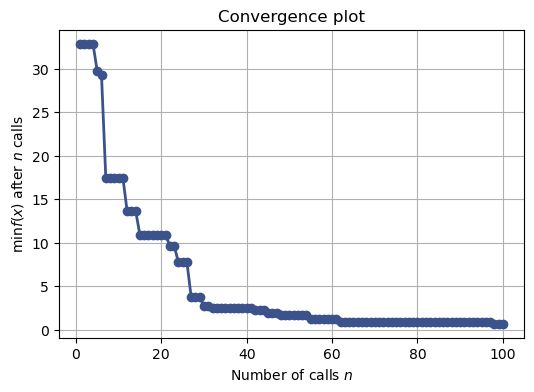

In [57]:
from skopt.plots import plot_convergence
plot_convergence(res);

In [11]:
plt.rcParams["figure.figsize"] = (8, 14)


def f_wo_noise(x):
    return f(x, noise_level=0)

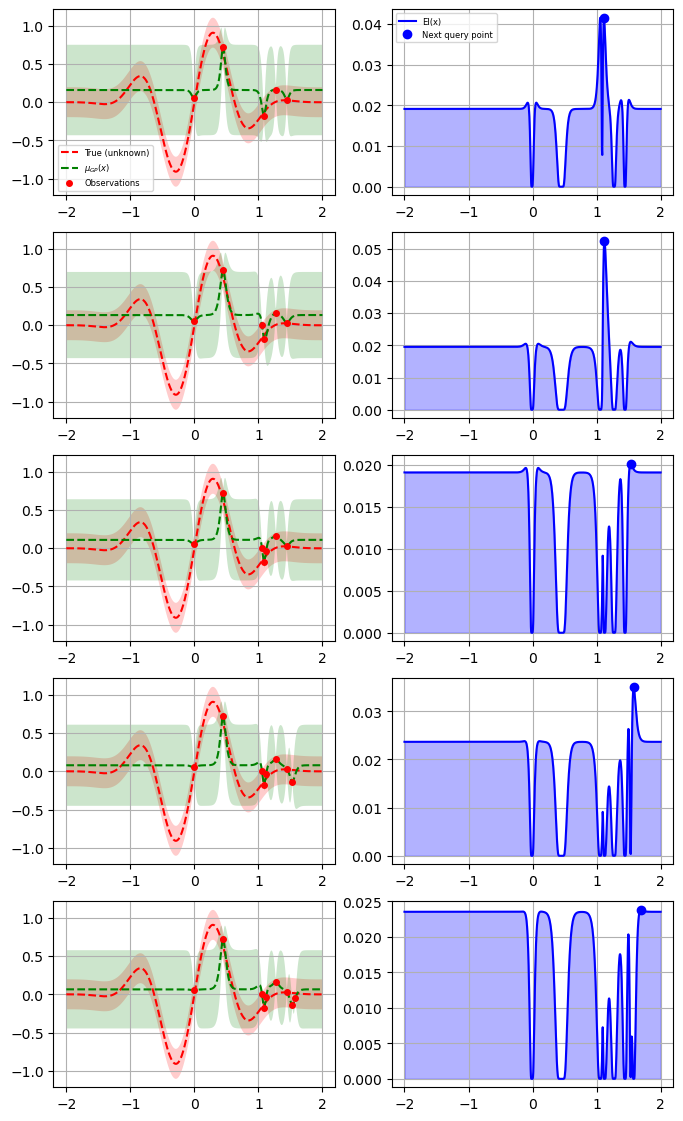

In [12]:
for n_iter in range(5):
    # Plot true function.
    plt.subplot(5, 2, 2*n_iter+1)

    if n_iter == 0:
        show_legend = True
    else:
        show_legend = False

    ax = plot_gaussian_process(res, n_calls=n_iter,
                               objective=f_wo_noise,
                               noise_level=noise_level,
                               show_legend=show_legend, show_title=False,
                               show_next_point=False, show_acq_func=False)
    ax.set_ylabel("")
    ax.set_xlabel("")
    # Plot EI(x)
    plt.subplot(5, 2, 2*n_iter+2)
    ax = plot_gaussian_process(res, n_calls=n_iter,
                               show_legend=show_legend, show_title=False,
                               show_mu=False, show_acq_func=True,
                               show_observations=False,
                               show_next_point=True)
    ax.set_ylabel("")
    ax.set_xlabel("")

plt.show()

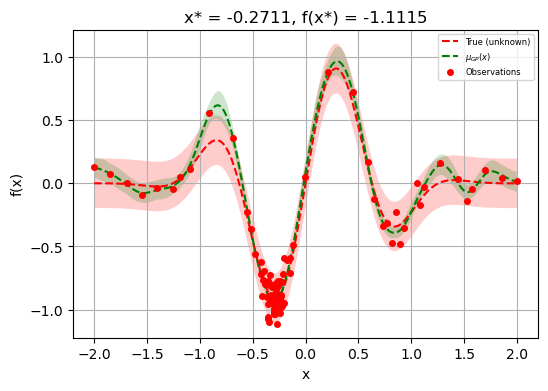

In [13]:
plt.rcParams["figure.figsize"] = (6, 4)

# Plot f(x) + contours
_ = plot_gaussian_process(res, objective=f_wo_noise,
                          noise_level=noise_level)

plt.show()